# BI10 | Challenge 1 — Bước 3.3: Incremental Feature Evidence
**Đầu vào:** `C1_STEP3_OUTPUT/run_*/tables/03_customer_feature_mart.csv` từ bước 3.2 và `clean_data/CONTRACT_clean.csv`.  
**Mục tiêu:** kiểm tra A2 bổ sung gì ngoài A1; A3 bổ sung gì ngoài A1+A2; P2 bổ sung gì ngoài P1. Kiểm tra sai lệch chọn mẫu, khác biệt sản phẩm và tương quan trùng lặp.  
**Đầu ra:** chỉ gồm bảng thống kê, kiểm định gia tăng và biểu đồ — **chưa xây score hay trọng số**.

Các kết quả bên dưới là **liên hệ cùng quan sát** (*contemporaneous association*), **không phải dự báo nợ xấu tương lai**. `AMT_INCOME_MAIN` chưa xác nhận là thu nhập tháng; cohort theo ngày nộp đơn không phải thời điểm phát sinh DUE/Written off.

### 1. Thiết lập — đọc file của bước 3.2, không kết nối DuckDB đang sử dụng

In [1]:
from pathlib import Path
from datetime import datetime
from uuid import uuid4
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Chỉ điền nếu notebook đặt ngoài thư mục dữ liệu BI10.
S33_FEATURE_MART_PATH = None
S33_CLEAN_CONTRACT_PATH = None
S33_MODEL_MAX_ROWS = 180_000  # Giới hạn RAM; chọn mẫu khách hàng xác định bằng hash.
S33_MIN_EVENTS = 30

if S33_FEATURE_MART_PATH:
    MART = Path(S33_FEATURE_MART_PATH).expanduser().resolve()
else:
    roots = [Path.cwd(), *list(Path.cwd().parents)[:3]]
    parents = [r / sub for r in roots for sub in ('C1_STEP3_OUTPUT', 'BI10_ROUND02_DATASET/C1_STEP3_OUTPUT')]
    paths = [p for root in parents if root.is_dir()
             for p in root.glob('run_*/tables/03_customer_feature_mart.csv')]
    if not paths:
        raise FileNotFoundError('Không tìm thấy 03_customer_feature_mart.csv trong C1_STEP3_OUTPUT/run_*/tables/')
    MART = max(paths, key=lambda p: p.stat().st_mtime).resolve()
if not MART.is_file():
    raise FileNotFoundError(MART)

CLEAN_CONTRACT = (Path(S33_CLEAN_CONTRACT_PATH).expanduser().resolve()
    if S33_CLEAN_CONTRACT_PATH else MART.parents[3] / 'clean_data' / 'CONTRACT_clean.csv')
if not CLEAN_CONTRACT.is_file():
    raise FileNotFoundError(f'Không tìm thấy CONTRACT_clean.csv: {CLEAN_CONTRACT}')

OUT = MART.parents[1] / ('STEP33_' + datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid4().hex[:5])
TABLES, TMP, FIGS = OUT / 'tables', OUT / 'scratch', OUT / 'figures'
for p in (TABLES, TMP, FIGS): p.mkdir(parents=True, exist_ok=True)
DB = duckdb.connect(':memory:')
DB.execute('SET threads=4')
DB.execute("SET memory_limit='4GB'")
DB.execute('SET preserve_insertion_order=false')

def q(p):
    return "'" + Path(p).resolve().as_posix().replace("'", "''") + "'"
DB.execute('SET temp_directory=' + q(TMP))

def show_save(name, sql, n=16):
    df = DB.execute(sql).df()
    df.to_csv(TABLES / f'{name}.csv', index=False, encoding='utf-8-sig')
    print(f'\n{name} — {len(df):,} dòng')
    display(df.head(n))
    return df

print('Đọc Feature Mart:', MART)
print('Đọc hợp đồng đã clean:', CLEAN_CONTRACT)
print('Chỉ ghi kết quả mới tại:', OUT)

Đọc Feature Mart: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP3_OUTPUT\run_20261018_091425_849a72\tables\03_customer_feature_mart.csv
Đọc hợp đồng đã clean: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\clean_data\CONTRACT_clean.csv
Chỉ ghi kết quả mới tại: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP3_OUTPUT\run_20261018_091425_849a72\STEP33_20261018_094108_08f99


### 2. Kiểm tra schema, chuẩn hóa 6 biến và ghi bản tạm chỉ đọc

**Lưu ý:** Code tự chuẩn hóa tên A3 do DuckDB xử lý bí danh không phân biệt chữ hoa/thường; không thay đổi Feature Mart gốc.


In [2]:
DB.execute(f'''CREATE VIEW s33_mart_csv AS SELECT * FROM read_csv(
    {q(MART)}, header=true, all_varchar=true, delim=',', quote='"', escape='"', ignore_errors=false
)''')
# Bước 3.2 xuất cả a3_active_case_count (nguồn) và bí danh A3_ACTIVE_CASE_COUNT.
# DuckDB không phân biệt hoa/thường, nên bí danh có thể bị đổi tên thành *_1.
# Chuẩn hóa cột A3 khi đọc, KHÔNG sửa dữ liệu hoặc tính lại từ CSV hợp đồng.
mart_columns = [x[0] for x in DB.execute('SELECT * FROM s33_mart_csv LIMIT 0').description]
name_lookup = {c.casefold(): c for c in mart_columns}

required = {
    'client_id', 'A1_ODSR_IF_INCOME_MONTHLY', 'A2_RESIDUAL_IF_INCOME_MONTHLY',
    'P1_DUE_RATE_RESOLVED_PROXY', 'P2_DUE_FLAG_BREADTH_AMONG_AFFECTED',
    'P3_WRITTEN_OFF_HISTORY', 'n_payment_observable_resolved_proxy',
    'n_due_resolved_proxy', 'n_signed_cases',
    'n_active_cases_missing_annuity', 'income_source_product',
    'income_period_monthly_confirmed'
}
missing = sorted(c for c in required if c.casefold() not in name_lookup)
if missing:
    raise ValueError('Feature Mart thiếu cột: ' + ', '.join(missing))

_a3_aliases = ['a3_active_case_count', 'A3_ACTIVE_CASE_COUNT_1',
               'A3_ACTIVE_CASE_COUNT', 'a3_active_case_count_1']
_a3_found = list(dict.fromkeys(name_lookup[c.casefold()] for c in _a3_aliases
                               if c.casefold() in name_lookup))
if not _a3_found:
    raise ValueError('Không thấy dữ liệu A3. Các cột Feature Mart: ' + ', '.join(mart_columns))

def quote_identifier(name):
    return '"' + name.replace('"', '""') + '"'

_a3_column = _a3_found[0]
# Nếu có hai tên A3, đảm bảo chúng thực sự trùng nhau trước khi chọn.
for _other in _a3_found[1:]:
    _n_diff = DB.execute(f'''SELECT COUNT(*)
        FROM s33_mart_csv
        WHERE TRY_CAST({quote_identifier(_a3_column)} AS BIGINT)
          IS DISTINCT FROM TRY_CAST({quote_identifier(_other)} AS BIGINT)''').fetchone()[0]
    if _n_diff:
        raise ValueError(f'Cột A3 không khớp giữa {_a3_column} và {_other}: {_n_diff} dòng.')
print('Cột A3 nguồn:', _a3_column)
print('Cột trong Feature Mart:', ', '.join(mart_columns))

MART_PARQUET = TMP / 'feature_mart_33.parquet'
DB.execute(f'''COPY (
  SELECT TRIM(client_id) AS client_id,
    TRY_CAST(A1_ODSR_IF_INCOME_MONTHLY AS DOUBLE) AS a1,
    TRY_CAST(A2_RESIDUAL_IF_INCOME_MONTHLY AS DOUBLE) AS a2,
    TRY_CAST({quote_identifier(_a3_column)} AS INTEGER) AS a3,
    TRY_CAST(P1_DUE_RATE_RESOLVED_PROXY AS DOUBLE) AS p1,
    TRY_CAST(P2_DUE_FLAG_BREADTH_AMONG_AFFECTED AS DOUBLE) AS p2,
    TRY_CAST(P3_WRITTEN_OFF_HISTORY AS INTEGER) AS p3,
    TRY_CAST(n_payment_observable_resolved_proxy AS INTEGER) AS n_payment,
    TRY_CAST(n_due_resolved_proxy AS INTEGER) AS n_due,
    TRY_CAST(n_signed_cases AS INTEGER) AS n_signed,
    TRY_CAST(n_active_cases_missing_annuity AS INTEGER) AS n_active_missing_annuity,
    NULLIF(UPPER(TRIM(income_source_product)),'') AS product_context,
    TRY_CAST(income_period_monthly_confirmed AS BOOLEAN) AS income_monthly_confirmed
  FROM s33_mart_csv
) TO {q(MART_PARQUET)} (FORMAT PARQUET, COMPRESSION ZSTD)''')
DB.execute(f'CREATE VIEW s33_mart AS SELECT * FROM read_parquet({q(MART_PARQUET)})')

check = show_save('00_input_integrity', '''
SELECT COUNT(*) AS n_customers, COUNT(DISTINCT client_id) AS n_unique_clients,
       COUNT(*) FILTER (WHERE client_id IS NULL OR client_id='') AS null_clients,
       COUNT(*) FILTER (WHERE a1<0 OR NOT isfinite(a1)) AS invalid_a1,
       COUNT(*) FILTER (WHERE p1<0 OR p1>1) AS invalid_p1,
       COUNT(*) FILTER (WHERE p2<1 OR p2>4) AS invalid_p2,
       COUNT(*) FILTER (WHERE p3 NOT IN (0,1)) AS invalid_p3,
       COUNT(*) FILTER (WHERE income_monthly_confirmed) AS n_income_period_confirmed
FROM s33_mart''')
r = check.iloc[0]
if r.n_customers != r.n_unique_clients or any(int(r[k]) for k in
    ['null_clients','invalid_a1','invalid_p1','invalid_p2','invalid_p3']):
    raise ValueError('Kiểm tra đầu vào thất bại; xem 00_input_integrity.csv')

Cột A3 nguồn: a3_active_case_count
Cột trong Feature Mart: SKP_CLIENT, client_id, n_all_cases, n_integrity_failed_cases, n_signed_cases, a3_active_case_count, n_active_cases_with_annuity, n_active_cases_missing_annuity, active_annuity_known, n_payment_observable_resolved_proxy, n_due_resolved_proxy, n_due_flags_affected_cases, n_payment_observable_signed_proxy, n_due_signed_proxy, n_written_off_cases, income_candidate, income_source_application_time, income_source_product, latest_income_recon_class, n_income_source_cases, min_reported_income, max_reported_income, A1_ODSR_IF_INCOME_MONTHLY, A2_RESIDUAL_IF_INCOME_MONTHLY, A3_ACTIVE_CASE_COUNT_1, P1_DUE_RATE_RESOLVED_PROXY, P2_DUE_FLAG_BREADTH_AMONG_AFFECTED, P3_WRITTEN_OFF_HISTORY, income_spread_across_cases, capacity_data_complete_proxy, payment_observed_resolved_proxy, income_period_monthly_confirmed

00_input_integrity — 1 dòng


,n_customers,n_unique_clients,null_clients,invalid_a1,invalid_p1,invalid_p2,invalid_p3,n_income_period_confirmed
0,1000528,1000528,0,0,0,0,0,0


### 3. Tạo bằng chứng Payment **không sử dụng case Written off** khi đối chiếu với P3  
Đây là kiểm tra giảm trùng lặp định nghĩa; **không loại bỏ được sai lệch thời gian hoặc quan hệ nhân quả**.

In [3]:
DB.execute(f'''CREATE VIEW s33_contract_csv AS SELECT * FROM read_csv(
    {q(CLEAN_CONTRACT)}, header=true, all_varchar=true,
    delim=',', quote='"', escape='"', ignore_errors=false
)''')
need = {'SKP_CLIENT','SKP_CREDIT_CASE','NAME_CREDIT_STATUS',
        'FIRST_DUE','SECOND_DUE','THIRD_DUE','FOURTH_DUE','APPLY_CONTRACT_TIME'}
actual = {c[0] for c in DB.execute('SELECT * FROM s33_contract_csv LIMIT 0').description}
if absent := need - actual:
    raise ValueError('CONTRACT_clean.csv thiếu cột: ' + ', '.join(sorted(absent)))

CONTRACT_PROFILE = TMP / 'contract_payment_nonwo.parquet'
DB.execute(f'''COPY (
WITH parsed AS (
    SELECT TRIM(SKP_CLIENT) AS client_id, NULLIF(TRIM(SKP_CREDIT_CASE),'') AS case_id,
        UPPER(TRIM(NAME_CREDIT_STATUS)) AS st,
        TRY_CAST(FIRST_DUE AS INTEGER) AS d1, TRY_CAST(SECOND_DUE AS INTEGER) AS d2,
        TRY_CAST(THIRD_DUE AS INTEGER) AS d3, TRY_CAST(FOURTH_DUE AS INTEGER) AS d4,
        TRY_CAST(APPLY_CONTRACT_TIME AS TIMESTAMP) AS apply_ts
    FROM s33_contract_csv
), flags AS (
    SELECT *, (d1 IN (0,1) AND d2 IN (0,1) AND d3 IN (0,1) AND d4 IN (0,1)) AS valid_due,
           COALESCE(d1,0)+COALESCE(d2,0)+COALESCE(d3,0)+COALESCE(d4,0) AS due_flags
    FROM parsed
)
SELECT client_id,
    COUNT(*) AS n_case_clean,
    COUNT(DISTINCT case_id) AS n_unique_case_clean,
    COUNT(*) FILTER (WHERE st='WRITTEN OFF') AS n_writtenoff_clean,
    COUNT(*) FILTER (WHERE st='ACTIVE') AS n_active_clean,
    COUNT(*) FILTER (WHERE st IN ('FINISHED','PAID OFF') AND valid_due) AS n_nonwo_eligible,
    COUNT(*) FILTER (WHERE st IN ('FINISHED','PAID OFF') AND valid_due AND due_flags>0) AS n_nonwo_due,
    SUM(due_flags) FILTER (WHERE st IN ('FINISHED','PAID OFF') AND valid_due AND due_flags>0)
        AS n_nonwo_due_flags,
    MIN(YEAR(apply_ts)) AS first_apply_year
FROM flags WHERE client_id IS NOT NULL AND client_id<>''
GROUP BY client_id
) TO {q(CONTRACT_PROFILE)} (FORMAT PARQUET, COMPRESSION ZSTD)''')
DB.execute(f'CREATE VIEW s33_contract_profile AS SELECT * FROM read_parquet({q(CONTRACT_PROFILE)})')

# JOIN tạo bản tạm, KHÔNG thay đổi Feature Mart của bước 3.2.
ENRICH = TMP / 'customer_analysis_33.parquet'
DB.execute(f'''COPY (
SELECT m.*,
   COALESCE(c.n_case_clean,0) AS n_case_clean,
   COALESCE(c.n_unique_case_clean,0) AS n_unique_case_clean,
   COALESCE(c.n_writtenoff_clean,0) AS n_writtenoff_clean,
   COALESCE(c.n_active_clean,0) AS n_active_clean,
   c.n_nonwo_eligible, c.n_nonwo_due, c.n_nonwo_due_flags, c.first_apply_year,
   CASE WHEN c.n_nonwo_eligible>0 THEN COALESCE(c.n_nonwo_due,0)::DOUBLE/c.n_nonwo_eligible END AS p1_excluding_wo,
   CASE WHEN c.n_nonwo_due>0 THEN c.n_nonwo_due_flags::DOUBLE/c.n_nonwo_due END AS p2_excluding_wo,
   CASE WHEN m.n_payment>0 THEN CAST(COALESCE(m.n_due,0)>0 AS INTEGER) END AS has_due,
   CASE WHEN c.first_apply_year IS NULL THEN 'UNKNOWN'
        WHEN c.first_apply_year<=2016 THEN '<=2016'
        WHEN c.first_apply_year<=2020 THEN '2017-20'
        WHEN c.first_apply_year<=2023 THEN '2021-23'
        ELSE '2024+' END AS cohort_group,
   CASE WHEN m.a1 IS NULL THEN 'MISSING'
        WHEN m.a1<0.10 THEN '00-10%'
        WHEN m.a1<0.20 THEN '10-20%'
        WHEN m.a1<0.30 THEN '20-30%'
        WHEN m.a1<0.40 THEN '30-40%'
        WHEN m.a1<0.50 THEN '40-50%'
        WHEN m.a1<1 THEN '50-100%' ELSE '>=100%' END AS ratio_band,
   CASE WHEN m.a3=0 THEN '0' WHEN m.a3=1 THEN '1'
        WHEN m.a3=2 THEN '2' ELSE '3+' END AS active_band,
   COALESCE(m.product_context,'UNKNOWN') AS product_group
FROM s33_mart m LEFT JOIN s33_contract_profile c USING (client_id)
) TO {q(ENRICH)} (FORMAT PARQUET, COMPRESSION ZSTD)''')
DB.execute(f'CREATE VIEW s33 AS SELECT * FROM read_parquet({q(ENRICH)})')

recheck = show_save('01_nonwo_consistency', '''
SELECT COUNT(*) AS clients, SUM(n_case_clean) AS clean_case_records,
       SUM(n_unique_case_clean) AS unique_case_records,
       COUNT(*) FILTER (WHERE n_case_clean<>n_unique_case_clean) AS clients_with_duplicate_cases,
       COUNT(*) FILTER (WHERE n_active_clean<>COALESCE(a3,0)) AS active_count_mismatch,
       COUNT(*) FILTER (WHERE p3 IS NOT NULL AND p3<>CAST(n_writtenoff_clean>0 AS INTEGER)) AS writtenoff_mismatch,
       COUNT(*) FILTER (WHERE p1_excluding_wo IS NOT NULL) AS n_nonwo_p1,
       COUNT(*) FILTER (WHERE p2_excluding_wo IS NOT NULL) AS n_nonwo_p2
FROM s33''')
if int(recheck.clients_with_duplicate_cases.iloc[0]) or int(recheck.active_count_mismatch.iloc[0]) or int(recheck.writtenoff_mismatch.iloc[0]):
    raise ValueError('CLEAN Contract và Feature Mart không nhất quán; xem 01_nonwo_consistency.csv')


01_nonwo_consistency — 1 dòng


,clients,clean_case_records,unique_case_records,clients_with_duplicate_cases,active_count_mismatch,writtenoff_mismatch,n_nonwo_p1,n_nonwo_p2
0,1000528,4280377.0,4280377.0,0,0,0,636994,29307


### 4. Mẫu số, coverage, tương quan trùng lặp  
`P2` chỉ xác định ở khách hàng có ít nhất một case DUE; NULL không có nghĩa DUE bằng 0.

In [4]:
availability = show_save('02_feature_coverage', '''
SELECT COUNT(*) AS n_total,
 COUNT(*) FILTER (WHERE a1 IS NOT NULL) AS n_a1,
 COUNT(*) FILTER (WHERE a2 IS NOT NULL) AS n_a2,
 COUNT(*) FILTER (WHERE a3 IS NOT NULL) AS n_a3,
 COUNT(*) FILTER (WHERE p1 IS NOT NULL) AS n_p1,
 COUNT(*) FILTER (WHERE p2 IS NOT NULL) AS n_p2_conditional,
 COUNT(*) FILTER (WHERE p3 IS NOT NULL) AS n_p3,
 COUNT(*) FILTER (WHERE a1 IS NOT NULL AND has_due IS NOT NULL) AS n_capacity_with_due,
 COUNT(*) FILTER (WHERE a1 IS NOT NULL AND p3 IS NOT NULL) AS n_capacity_with_wo,
 COUNT(*) FILTER (WHERE p2_excluding_wo IS NOT NULL AND p3 IS NOT NULL) AS n_p2_nonwo_with_wo,
 COUNT(*) FILTER (WHERE a1 IS NOT NULL AND n_active_missing_annuity>0) AS suspicious_ratio_with_missing_annuity
FROM s33''')

pairs_df = DB.execute('''SELECT a1,a2,a3,p1,p2,p3 FROM s33''').df()
features = list(pairs_df.columns)
correlations = []
for i, a in enumerate(features):
    for b in features[i+1:]:
        part = pairs_df[[a,b]].dropna()
        correlations.append(dict(feature_a=a,feature_b=b,n_pair=len(part),
            spearman_rho=(part[a].corr(part[b],method='spearman')
                          if len(part)>2 and part[a].nunique()>1 and part[b].nunique()>1 else np.nan)))
corr = pd.DataFrame(correlations)
corr.to_csv(TABLES/'03_pairwise_spearman.csv',index=False,encoding='utf-8-sig')
display(corr.sort_values('spearman_rho',key=lambda s:s.abs(),ascending=False).head(15))
del pairs_df


02_feature_coverage — 1 dòng


,n_total,n_a1,n_a2,n_a3,n_p1,n_p2_conditional,n_p3,n_capacity_with_due,n_capacity_with_wo,n_p2_nonwo_with_wo,suspicious_ratio_with_missing_annuity
0,1000528,590696,590696,1000528,643574,36366,818023,471605,590696,29307,0


,feature_a,feature_b,n_pair,spearman_rho
1,a1,a3,590696,0.878447
12,p1,p2,36366,0.332587
13,p1,p3,643574,0.327154
14,p2,p3,36366,0.312331
10,a3,p2,36366,-0.293029
3,a1,p2,31099,-0.286722
0,a1,a2,590696,-0.176636
11,a3,p3,818023,-0.175529
4,a1,p3,590696,-0.170056
9,a3,p1,643574,-0.140862


### 5. A1: đối chiếu ODSR với dấu hiệu thanh toán, theo nhóm sản phẩm  
`product_group` là **sản phẩm của hồ sơ nguồn thu nhập được chọn** ở bước 3.2, không đại diện toàn bộ sản phẩm khách hàng sử dụng.

In [5]:
a1_table = show_save('04_a1_ratio_vs_due', '''
SELECT product_group, ratio_band, COUNT(*) AS n_customers,
 COUNT(*) FILTER (WHERE has_due IS NOT NULL) AS n_due_observable,
 COUNT(*) FILTER (WHERE has_due=1) AS n_has_due,
 ROUND(100.0*COUNT(*) FILTER (WHERE has_due=1)
     /NULLIF(COUNT(*) FILTER (WHERE has_due IS NOT NULL),0),3) AS any_due_pct,
 COUNT(*) FILTER (WHERE p3 IS NOT NULL) AS n_wo_observable,
 COUNT(*) FILTER (WHERE p3=1) AS n_written_off,
 ROUND(100.0*COUNT(*) FILTER (WHERE p3=1)
     /NULLIF(COUNT(*) FILTER (WHERE p3 IS NOT NULL),0),3) AS writtenoff_pct
FROM s33 WHERE a1 IS NOT NULL
GROUP BY 1,2 ORDER BY 1,2''', n=50)


04_a1_ratio_vs_due — 36 dòng


,product_group,ratio_band,n_customers,n_due_observable,n_has_due,any_due_pct,n_wo_observable,n_written_off,writtenoff_pct
0,BNPL,00-10%,2408,2369,453,19.122,2408,139,5.772
1,BNPL,10-20%,389,375,39,10.400,389,0,0.000
2,BNPL,20-30%,178,174,16,9.195,178,0,0.000
3,BNPL,30-40%,83,82,4,4.878,83,0,0.000
4,BNPL,40-50%,22,22,1,4.545,22,0,0.000
5,BNPL,50-100%,20,20,0,0.000,20,0,0.000
6,CC,00-10%,3620,3614,471,13.033,3620,206,5.691
7,CC,10-20%,789,786,42,5.344,789,0,0.000
8,CC,20-30%,309,308,15,4.870,309,1,0.324
9,CC,30-40%,81,81,3,3.704,81,0,0.000


### 6. A2 và A3: kiểm tra **thông tin bổ sung sau khi giữ A1 ở cùng khoảng**

In [6]:
# Chia A2 thành 3 phần theo giá trị trong cùng nhóm ratio + nguồn sản phẩm.
# So sánh có điều kiện, không giả định quan hệ nhân quả.
A2_STRATA = '''
WITH eligible AS (
 SELECT product_group, ratio_band, a2, has_due, p3
 FROM s33 WHERE a1 IS NOT NULL AND a2 IS NOT NULL AND has_due IS NOT NULL
), bucketed AS (
 SELECT *, NTILE(3) OVER (PARTITION BY product_group,ratio_band ORDER BY a2) AS residual_tertile
 FROM eligible
)
SELECT product_group,ratio_band,residual_tertile,
 COUNT(*) AS n_customers, SUM(has_due) AS n_due,
 ROUND(100.0*AVG(has_due),3) AS any_due_pct,
 COUNT(*) FILTER (WHERE p3 IS NOT NULL) AS n_wo_obs,
 COUNT(*) FILTER (WHERE p3=1) AS n_wo,
 ROUND(100.0*COUNT(*) FILTER (WHERE p3=1)
      /NULLIF(COUNT(*) FILTER (WHERE p3 IS NOT NULL),0),3) AS writtenoff_pct,
 ROUND(MIN(a2),0) AS residual_min, ROUND(MAX(a2),0) AS residual_max
FROM bucketed GROUP BY 1,2,3 ORDER BY 1,2,3
'''
a2_bands=show_save('05_a2_within_a1',A2_STRATA,n=45)

# Với A3, chỉ so sánh người có >=1 Active; tránh trường hợp A1=0 do không có Active.
a3_bands=show_save('06_a3_within_a1', '''
SELECT product_group,ratio_band,active_band,
 COUNT(*) AS n_customers,
 COUNT(*) FILTER (WHERE has_due IS NOT NULL) AS n_due_obs,
 COUNT(*) FILTER (WHERE has_due=1) AS n_due,
 ROUND(100.0*COUNT(*) FILTER (WHERE has_due=1)
      /NULLIF(COUNT(*) FILTER (WHERE has_due IS NOT NULL),0),3) AS any_due_pct,
 COUNT(*) FILTER (WHERE p3=1) AS n_writtenoff,
 ROUND(100.0*COUNT(*) FILTER (WHERE p3=1)
      /NULLIF(COUNT(*) FILTER (WHERE p3 IS NOT NULL),0),3) AS writtenoff_pct
FROM s33 WHERE a1>0 AND a2 IS NOT NULL AND a3>=1
GROUP BY 1,2,3 ORDER BY 1,2,3''',n=55)


05_a2_within_a1 — 97 dòng


,product_group,ratio_band,residual_tertile,n_customers,n_due,any_due_pct,n_wo_obs,n_wo,writtenoff_pct,residual_min,residual_max
0,BNPL,00-10%,1,790,163.0,20.633,790,37,4.684,2000000.0,10000000.0
1,BNPL,00-10%,2,790,136.0,17.215,790,34,4.304,10000000.0,15000000.0
2,BNPL,00-10%,3,789,154.0,19.518,789,68,8.619,15000000.0,500000000.0
3,BNPL,10-20%,1,125,13.0,10.400,125,0,0.000,4005000.0,8655000.0
4,BNPL,10-20%,2,125,17.0,13.600,125,0,0.000,8658000.0,12434000.0
5,BNPL,10-20%,3,125,9.0,7.200,125,0,0.000,12438000.0,44992000.0
6,BNPL,20-30%,1,58,6.0,10.345,58,0,0.000,2649000.0,7291000.0
7,BNPL,20-30%,2,58,6.0,10.345,58,0,0.000,7345000.0,9534000.0
8,BNPL,20-30%,3,58,4.0,6.897,58,0,0.000,9943000.0,23167000.0
9,BNPL,30-40%,1,28,2.0,7.143,28,0,0.000,1837000.0,6199000.0



06_a3_within_a1 — 91 dòng


,product_group,ratio_band,active_band,n_customers,n_due_obs,n_due,any_due_pct,n_writtenoff,writtenoff_pct
0,BNPL,00-10%,1,266,257,15,5.837,0,0.000
1,BNPL,00-10%,2,7,6,0,0.000,0,0.000
2,BNPL,10-20%,1,350,338,36,10.651,0,0.000
3,BNPL,10-20%,2,37,35,3,8.571,0,0.000
4,BNPL,10-20%,3+,2,2,0,0.000,0,0.000
5,BNPL,20-30%,1,145,142,16,11.268,0,0.000
6,BNPL,20-30%,2,31,30,0,0.000,0,0.000
7,BNPL,20-30%,3+,2,2,0,0.000,0,0.000
8,BNPL,30-40%,1,54,54,4,7.407,0,0.000
9,BNPL,30-40%,2,24,23,0,0.000,0,0.000


### 7. P2: so sánh với P3 sau khi **loại Written off khỏi phần tạo P1/P2**  
Chỉ xét khách hàng có DUE trong các case Finished/Paid off; đây là phân tích **có điều kiện trên nhóm DUE-positive**, không đại diện toàn dân số.

In [7]:
p2_bands=show_save('07_p2_incremental_descriptive', '''
WITH eligible AS (
 SELECT p1_excluding_wo,p2_excluding_wo,p3,n_nonwo_eligible,product_group,
   CASE WHEN p1_excluding_wo<0.25 THEN '00-25%'
        WHEN p1_excluding_wo<0.50 THEN '25-50%'
        WHEN p1_excluding_wo<1.0 THEN '50-<100%' ELSE '100%' END AS p1_band,
   CASE WHEN p2_excluding_wo<1.5 THEN '1 to <1.5'
        WHEN p2_excluding_wo<2.5 THEN '1.5 to <2.5' ELSE '2.5 to 4' END AS p2_band,
   CASE WHEN n_nonwo_eligible=1 THEN '1 case'
        WHEN n_nonwo_eligible<=3 THEN '2-3 cases'
        WHEN n_nonwo_eligible<=9 THEN '4-9 cases' ELSE '10+ cases' END AS exposure_band
 FROM s33
 WHERE p2_excluding_wo IS NOT NULL AND p3 IS NOT NULL
)
SELECT product_group,p1_band,exposure_band,p2_band,
 COUNT(*) AS n_customers, SUM(p3) AS n_writtenoff,
 ROUND(100.0*AVG(p3),3) AS writtenoff_pct
FROM eligible GROUP BY 1,2,3,4 ORDER BY 1,2,3,4''',n=60)


07_p2_incremental_descriptive — 140 dòng


,product_group,p1_band,exposure_band,p2_band,n_customers,n_writtenoff,writtenoff_pct
0,BNPL,00-25%,10+ cases,1 to <1.5,91,0.0,0.000
1,BNPL,00-25%,10+ cases,1.5 to <2.5,15,0.0,0.000
2,BNPL,00-25%,10+ cases,2.5 to 4,4,0.0,0.000
3,BNPL,00-25%,4-9 cases,1 to <1.5,646,1.0,0.155
4,BNPL,00-25%,4-9 cases,1.5 to <2.5,126,0.0,0.000
5,BNPL,00-25%,4-9 cases,2.5 to 4,36,0.0,0.000
6,BNPL,100%,1 case,1 to <1.5,433,2.0,0.462
7,BNPL,100%,1 case,1.5 to <2.5,107,1.0,0.935
8,BNPL,100%,1 case,2.5 to 4,552,0.0,0.000
9,BNPL,100%,2-3 cases,1 to <1.5,10,0.0,0.000


### 8. Incremental Ablation — Logistic Regression dùng để **đo giá trị bổ sung**, không tạo score  
So sánh trên **cùng tập khách hàng và cùng holdout**. Chỉ báo cáo thay đổi AP và log-loss; không gọi là khả năng dự báo tương lai.

In [8]:
def make_model_frame(where_sql, columns, limit=S33_MODEL_MAX_ROWS):
    sql = f"SELECT {columns} FROM s33 WHERE {where_sql} ORDER BY HASH(client_id) LIMIT {int(limit)}"
    return DB.execute(sql).df()

def incremental_test(label, df, ycol, base, candidate, categoricals=('product_group','cohort_group')):
    df = df.copy()
    use = list(dict.fromkeys(base+[candidate]+[ycol]+list(categoricals)))
    df = df[use].dropna(subset=base+[candidate,ycol])
    if len(df)<500 or df[ycol].nunique()!=2 or int(df[ycol].sum())<S33_MIN_EVENTS:
        return dict(test=label,n_clients=len(df),n_events=int(df[ycol].sum()),status='INSUFFICIENT_EVENTS')
    for c in categoricals:
        df[c] = df[c].fillna('UNKNOWN').astype(str)
    cols = list(dict.fromkeys(base+[candidate]))
    X = pd.get_dummies(df[cols+list(categoricals)],columns=list(categoricals),dtype=float)
    X = X.replace([np.inf,-np.inf],np.nan)
    if X.isna().any().any():
        return dict(test=label,n_clients=len(df),n_events=int(df[ycol].sum()),status='INVALID_FEATURE_VALUES')
    y=df[ycol].astype(int).to_numpy()
    idx_train, idx_test = train_test_split(np.arange(len(df)),test_size=0.25,
        random_state=2026,stratify=y)
    n_te=int(y[idx_test].sum())
    if n_te<5:
        return dict(test=label,n_clients=len(df),n_events=int(y.sum()),status='TOO_FEW_HOLDOUT_EVENTS')
    results=[]
    predictions=[]
    for feature_set in (base,base+[candidate]):
        catcols = [col for col in X.columns if any(col.startswith(c+'_') for c in categoricals)]
        used = list(dict.fromkeys(feature_set + catcols))
        xtr=X.iloc[idx_train][used].to_numpy(dtype=float)
        xte=X.iloc[idx_test][used].to_numpy(dtype=float)
        scaler=StandardScaler()
        xtr=scaler.fit_transform(xtr)
        xte=scaler.transform(xte)
        model=LogisticRegression(solver='liblinear',max_iter=250,random_state=2026)
        model.fit(xtr,y[idx_train])
        pred=np.clip(model.predict_proba(xte)[:,1],1e-9,1-1e-9)
        predictions.append(pred)
        results.append((float(log_loss(y[idx_test],pred,labels=[0,1])),
                        float(average_precision_score(y[idx_test],pred)),
                        float(roc_auc_score(y[idx_test],pred))))
    (ll0,ap0,auc0),(ll1,ap1,auc1)=results
    # Paired bootstrap trên đúng holdout khách hàng; đo tính ổn định của cải thiện.
    rng=np.random.default_rng(2026)
    test_y=y[idx_test]
    improvements=[]
    for _ in range(80):
        ids=rng.integers(0,len(test_y),size=len(test_y))
        yy=test_y[ids]
        if yy.min()==yy.max():
            continue
        improvements.append((
            log_loss(yy,predictions[0][ids],labels=[0,1])-
            log_loss(yy,predictions[1][ids],labels=[0,1]),
            average_precision_score(yy,predictions[1][ids])-
            average_precision_score(yy,predictions[0][ids])
        ))
    bounds=np.quantile(np.asarray(improvements),[0.025,0.975],axis=0)
    return dict(test=label,n_clients=len(df),n_events=int(y.sum()),n_holdout_events=n_te,
        event_rate_pct=round(100*np.mean(y),3),base_logloss=round(ll0,6),extended_logloss=round(ll1,6),
        logloss_improvement=round(ll0-ll1,6),base_AP=round(ap0,5),extended_AP=round(ap1,5),
        AP_improvement=round(ap1-ap0,5),
        logloss_delta_ci_low=round(float(bounds[0,0]),6),
        logloss_delta_ci_high=round(float(bounds[1,0]),6),
        ap_delta_ci_low=round(float(bounds[0,1]),5),
        ap_delta_ci_high=round(float(bounds[1,1]),5),
        base_ROC_AUC=round(auc0,5),
        extended_ROC_AUC=round(auc1,5),status='DESCRIPTIVE_HOLDOUT_ONLY')

# Phi tuyến nhẹ, không đặt ngưỡng tín dụng; điều chỉnh đơn vị giúp hồi quy ổn định.
cap = make_model_frame('a1 IS NOT NULL AND a2 IS NOT NULL AND a3>=1 '
  'AND has_due IS NOT NULL AND p3 IS NOT NULL',
  "client_id, product_group, cohort_group, has_due, p3, "
  "LN(1+LEAST(a1,5)) AS ratio_x, "
  "ASINH(a2/10000000.0) AS residual_x, "
  "LN(1+a3) AS active_x, LN(1+GREATEST(n_payment,0)) AS exposure_x")
cap_tests=[]
for target in ['has_due','p3']:
    cap_tests.append(incremental_test('A2 beyond A1 → '+target,cap,target,
        ['ratio_x','exposure_x'],'residual_x'))
    cap_tests.append(incremental_test('A3 beyond A1+A2 → '+target,cap,target,
        ['ratio_x','residual_x','exposure_x'],'active_x'))

payment=make_model_frame('p2_excluding_wo IS NOT NULL AND p3 IS NOT NULL '
  'AND n_nonwo_eligible>0',
  "client_id, product_group, cohort_group, p3, "
  "p1_excluding_wo AS p1_nonwo_x, "
  "p2_excluding_wo AS p2_nonwo_x, "
  "LN(1+n_nonwo_eligible) AS exposure_x")
cap_tests.append(incremental_test('P2 beyond P1 (non-WO) → p3',payment,'p3',
    ['p1_nonwo_x','exposure_x'],'p2_nonwo_x'))

ablation=pd.DataFrame(cap_tests)
ablation.to_csv(TABLES/'08_incremental_ablation.csv',index=False,encoding='utf-8-sig')
print('08_incremental_ablation — cải thiện log-loss/AP trên holdout: dương = cải thiện mô tả')
display(ablation)

08_incremental_ablation — cải thiện log-loss/AP trên holdout: dương = cải thiện mô tả


,test,n_clients,n_events,n_holdout_events,event_rate_pct,base_logloss,extended_logloss,logloss_improvement,base_AP,extended_AP,AP_improvement,logloss_delta_ci_low,logloss_delta_ci_high,ap_delta_ci_low,ap_delta_ci_high,base_ROC_AUC,extended_ROC_AUC,status
0,A2 beyond A1 → has_due,180000,6136,1534,3.409,0.141471,0.141399,0.000071,0.05888,0.05986,0.00098,-0.000106,0.000283,0.00001,0.00196,0.68360,0.68420,DESCRIPTIVE_HOLDOUT_ONLY
1,A3 beyond A1+A2 → has_due,180000,6136,1534,3.409,0.141399,0.141386,0.000013,0.05986,0.05994,0.00008,0.000001,0.000023,0.00003,0.00015,0.68420,0.68435,DESCRIPTIVE_HOLDOUT_ONLY
2,A2 beyond A1 → p3,180000,37,9,0.021,0.001886,0.001871,0.000015,0.00118,0.00122,0.00004,-0.000033,0.000052,-0.00568,0.00431,0.59695,0.66249,DESCRIPTIVE_HOLDOUT_ONLY
3,A3 beyond A1+A2 → p3,180000,37,9,0.021,0.001871,0.001855,0.000016,0.00122,0.00111,-0.00011,0.000004,0.000033,-0.00104,0.00008,0.66249,0.69550,DESCRIPTIVE_HOLDOUT_ONLY
4,P2 beyond P1 (non-WO) → p3,29307,490,123,1.672,0.076332,0.076391,-0.000059,0.06473,0.07281,0.00808,-0.000621,0.000474,0.00109,0.01535,0.78160,0.77875,DESCRIPTIVE_HOLDOUT_ONLY


### 9. Kiểm tra chênh lệch độ bao phủ giữa nhóm có/không đủ dữ liệu và xuất kết quả


09_selection_bias — 4 dòng


,a1_coverage,p1_coverage,n_customers,n_wo_observable,n_written_off,writtenoff_pct,mean_active_cases,pct_with_missing_active_annuity
0,A1 available,P1 available,471605,471605,13149,2.788,0.680,0.00
1,A1 available,P1 unavailable,119091,119091,0,0.000,1.058,0.00
2,A1 unavailable,P1 available,171969,171969,170,0.099,1.781,99.95
3,A1 unavailable,P1 unavailable,237863,55358,0,0.000,0.397,23.27


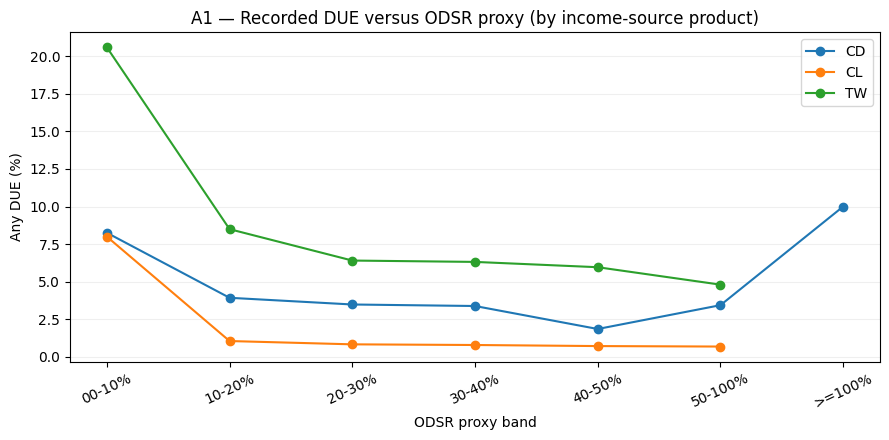

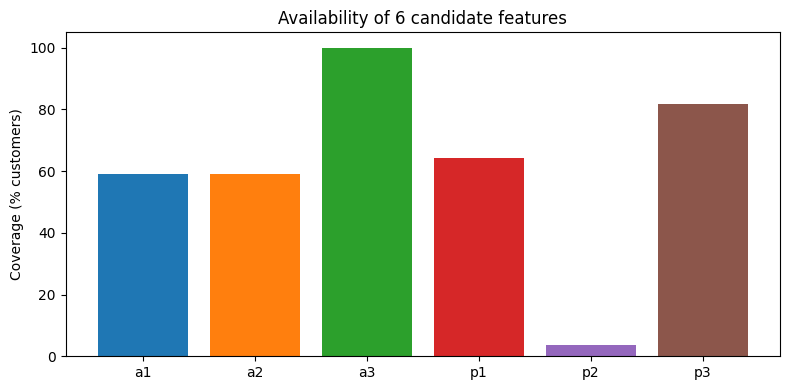


HOÀN THÀNH BƯỚC 3.3 — Chưa chấm điểm / chưa chọn trọng số
Bảng thống kê: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP3_OUTPUT\run_20261018_091425_849a72\STEP33_20261018_094108_08f99\tables
Biểu đồ: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP3_OUTPUT\run_20261018_091425_849a72\STEP33_20261018_094108_08f99\figures
Ghi chú phương pháp: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\C1_STEP3_OUTPUT\run_20261018_091425_849a72\STEP33_20261018_094108_08f99\S33_EVIDENCE_README.md


In [9]:
selection=show_save('09_selection_bias', '''
SELECT CASE WHEN a1 IS NOT NULL THEN 'A1 available' ELSE 'A1 unavailable' END AS a1_coverage,
 CASE WHEN p1 IS NOT NULL THEN 'P1 available' ELSE 'P1 unavailable' END AS p1_coverage,
 COUNT(*) AS n_customers,
 COUNT(*) FILTER (WHERE p3 IS NOT NULL) AS n_wo_observable,
 COUNT(*) FILTER (WHERE p3=1) AS n_written_off,
 ROUND(100.0*COUNT(*) FILTER (WHERE p3=1)
  / NULLIF(COUNT(*) FILTER (WHERE p3 IS NOT NULL),0),3) AS writtenoff_pct,
 ROUND(AVG(a3),3) AS mean_active_cases,
 ROUND(100.0*COUNT(*) FILTER (WHERE n_active_missing_annuity>0)/COUNT(*),2)
 AS pct_with_missing_active_annuity
FROM s33 GROUP BY 1,2 ORDER BY 1,2''')

# Ba biểu đồ từ bảng đã tính, không vẽ dữ liệu cá nhân.
fig,ax=plt.subplots(figsize=(9,4.5))
order=['00-10%','10-20%','20-30%','30-40%','40-50%','50-100%','>=100%']
for prod in ['CD','CL','TW']:
    s=a1_table[(a1_table.product_group==prod)&(a1_table.ratio_band.isin(order))]
    s=s.set_index('ratio_band').reindex(order)
    ax.plot(order,s['any_due_pct'],marker='o',label=prod)
ax.set(xlabel='ODSR proxy band',ylabel='Any DUE (%)',title='A1 — Recorded DUE versus ODSR proxy (by income-source product)')
ax.legend();ax.grid(axis='y',alpha=.2);plt.xticks(rotation=25);plt.tight_layout()
plt.savefig(FIGS/'01_a1_due_by_product.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(8,4))
for c in ['a1','a2','a3','p1','p2','p3']:
    n=DB.execute(f'SELECT COUNT(*) FILTER (WHERE {c} IS NOT NULL) FROM s33').fetchone()[0]
    ax.bar(c,100*n/int(availability.n_total.iloc[0]))
ax.set(ylabel='Coverage (% customers)',ylim=(0,105),title='Availability of 6 candidate features')
plt.tight_layout();plt.savefig(FIGS/'02_feature_coverage.png',dpi=160);plt.show()

notes = [
 '# BI10 Challenge 1 — Step 3.3 | Incremental Feature Evidence',
 '', f'Input mart: `{MART}`',f'Clean contracts: `{CLEAN_CONTRACT}`','',
 '## Rules of interpretation',
 '- A1/A2 remain proxy measures until income period and active-obligation timing are verified.',
 '- A2 = income - annuity is algebraically linked to A1; incremental association is not independent construct validity.',
 '- A3 is a count, not proof that more credit lines are financially harmful.',
 '- P2 is conditional on due-positive cases and is not measured for the entire population.',
 '- For P2 against Written off, DUE inputs from Written off cases are excluded to reduce mechanical overlap.',
 '- The outcomes are recorded in the same historical extract; holdout tests are descriptive, NOT temporal predictions.',
 '- Product group denotes product of the selected income-source case, not the complete customer portfolio.',
 '', '## Generated evidence tables'
] + [f'- `{p.name}`' for p in sorted(TABLES.glob('*.csv'))] + [
 '', '## Candidate decisions',
 'Review A2 vs A1; A3 vs A1+A2; P2 vs P1 non-WO. Feature acceptance is NOT automated from p-values or AUC alone.',
 'Independent target dates, outcome maturity, cost-of-living and complete external debt are not available.'
]
(OUT/'S33_EVIDENCE_README.md').write_text('\n'.join(notes),encoding='utf-8')
print('\nHOÀN THÀNH BƯỚC 3.3 — Chưa chấm điểm / chưa chọn trọng số')
print('Bảng thống kê:',TABLES)
print('Biểu đồ:',FIGS)
print('Ghi chú phương pháp:',OUT/'S33_EVIDENCE_README.md')
DB.close()